# Q1C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`). Every statistic below is computed on the training rows only.

# Answer Summary

# Imports

In [1]:
# Imports
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.special import logit
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, SplineTransformer

from Q1.consts import *

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Attribute vs Attribute

## Scatter Matrix

array([[<Axes: xlabel='Ladder', ylabel='Ladder'>,
        <Axes: xlabel='GDP', ylabel='Ladder'>,
        <Axes: xlabel='Social', ylabel='Ladder'>,
        <Axes: xlabel='Life exp', ylabel='Ladder'>,
        <Axes: xlabel='Freedom', ylabel='Ladder'>,
        <Axes: xlabel='Generosity', ylabel='Ladder'>,
        <Axes: xlabel='Corruption', ylabel='Ladder'>,
        <Axes: xlabel='Pos affect', ylabel='Ladder'>,
        <Axes: xlabel='Neg affect', ylabel='Ladder'>],
       [<Axes: xlabel='Ladder', ylabel='GDP'>,
        <Axes: xlabel='GDP', ylabel='GDP'>,
        <Axes: xlabel='Social', ylabel='GDP'>,
        <Axes: xlabel='Life exp', ylabel='GDP'>,
        <Axes: xlabel='Freedom', ylabel='GDP'>,
        <Axes: xlabel='Generosity', ylabel='GDP'>,
        <Axes: xlabel='Corruption', ylabel='GDP'>,
        <Axes: xlabel='Pos affect', ylabel='GDP'>,
        <Axes: xlabel='Neg affect', ylabel='GDP'>],
       [<Axes: xlabel='Ladder', ylabel='Social'>,
        <Axes: xlabel='GDP', ylabel='Social

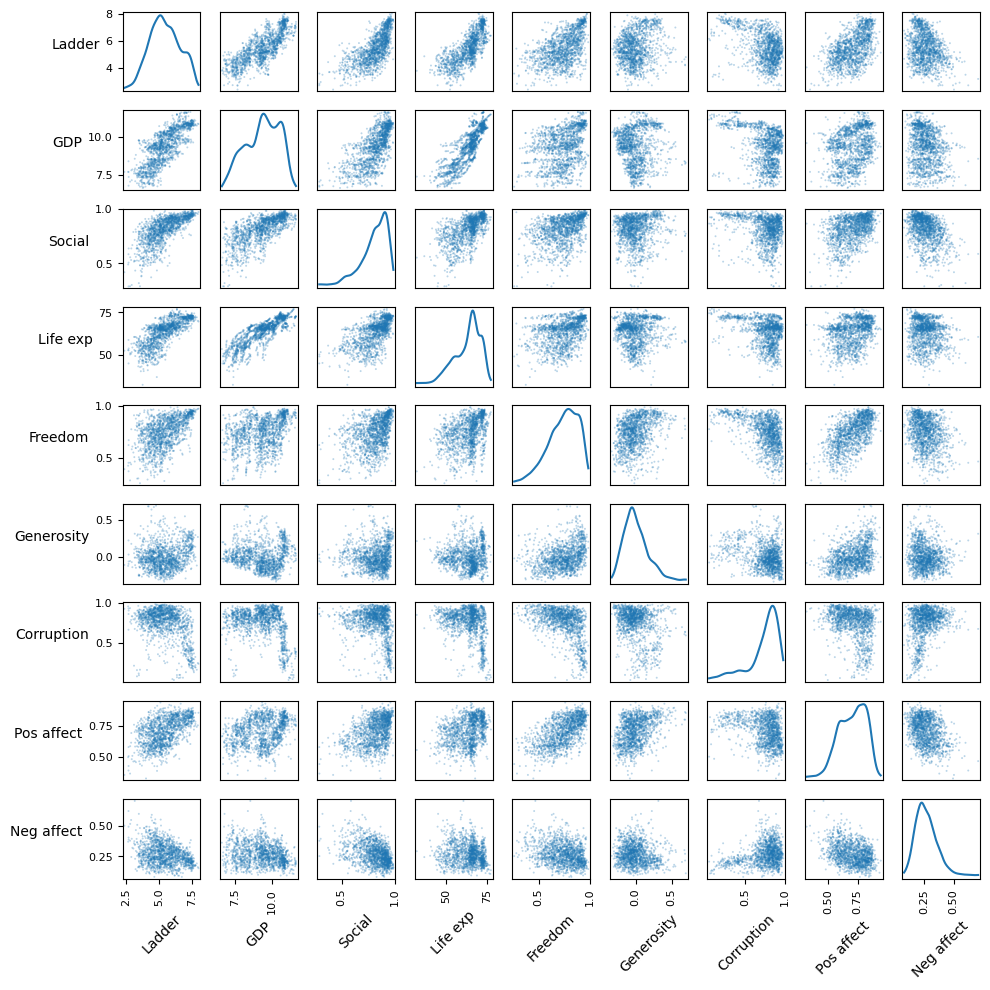

In [3]:
PLOTTING.scatter_matrix(df=train_df, labels=SHORT_NAMES)

## Correlation

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) CorrelaMatrix (train)'}>

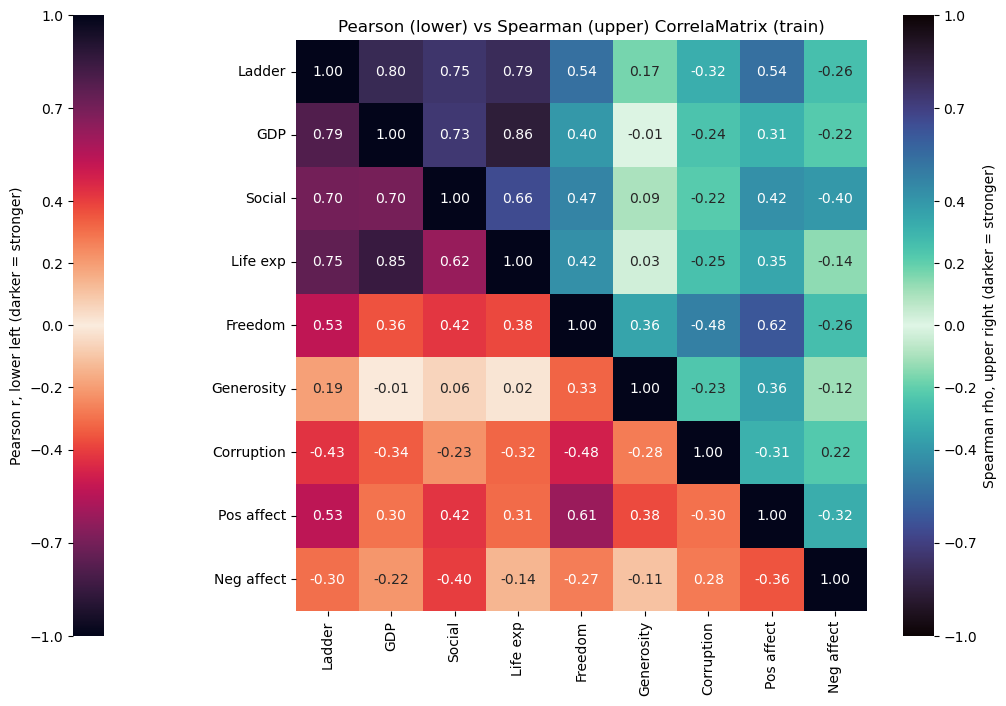

In [4]:
PLOTTING.correlation_matrix(
      pearson=train_df.corr(),
      spearman=train_df.corr(method='spearman'),
      labels=SHORT_NAMES,
      title='Pearson (lower) vs Spearman (upper) CorrelaMatrix (train)',
)

### Collinearity

In [5]:
STATISTICS.collinearity_df(df=train_df.drop(columns=TARGET),
													 # feature_pearson_threshold=0.7, filter=True # defaults
)

,rows used,Pearson r between features,|r| between features > 0.7,outcome
Log GDP per capita + Healthy life expectancy at birth,1509,0.851,True,"redundant: keep one, or use Ridge"


In [6]:
STATISTICS.combination_gain_df(df=train_df, target=train_df[TARGET],
															 # size=2, cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
Log GDP per capita + Positive affect,1516,Log GDP per capita,Positive affect,0.787,0.847,0.060,0.800,0.858,0.058,0.346,True,keep together
Healthy life expectancy at birth + Positive affect,1505,Healthy life expectancy at birth,Positive affect,0.753,0.816,0.063,0.791,0.840,0.049,0.296,True,keep together
Social support + Healthy life expectancy at birth,1512,Healthy life expectancy at birth,Social support,0.751,0.810,0.060,0.788,0.847,0.060,0.271,True,keep together
Log GDP per capita + Freedom to make life choices,1511,Log GDP per capita,Freedom to make life choices,0.788,0.830,0.042,0.802,0.839,0.037,0.219,True,keep together
Healthy life expectancy at birth + Freedom to make life choices,1500,Healthy life expectancy at birth,Freedom to make life choices,0.752,0.798,0.046,0.790,0.828,0.038,0.197,True,keep together
Social support + Perceptions of corruption,1468,Social support,Perceptions of corruption,0.709,0.760,0.051,0.755,0.760,0.005,0.177,True,keep together
Social support + Positive affect,1540,Social support,Positive affect,0.704,0.750,0.046,0.748,0.783,0.035,0.153,True,keep together
Social support + Freedom to make life choices,1532,Social support,Freedom to make life choices,0.705,0.750,0.045,0.748,0.779,0.031,0.151,True,keep together


In [ ]:
STATISTICS.combination_gain_df(df=train_df, target=train_df[TARGET], size=3,
															 # cohen_f2_threshold=0.15, filter=True # defaults
)

# Attribute Interventions